# Hockey project: 2. Regression: ranking NHL teams by points per game

Predicting the points per game (ppg) of every team in the coming season and sorting the teams into a league ranking, using only information available the day before the season starts.

*FEUP Master, Machine Learning. Notebook 2 of 4 (before: 1_eda; next: 3_classification, 4_feature_selection).*

**Contents**

| Section | Topic | CRISP-DM phase |
|---|---|---|
| 1 | Goal, data and metrics | Modeling |
| 2 | Baselines | Modeling |
| 3 | Nine algorithms | Modeling |
| 4 | Tuning and validation curves | Modeling |
| 5 | Comparison on the evaluation seasons, significance tests | Evaluation |
| 6 | Overfitting analysis and learning curve | Evaluation |
| 7 | Model improvement | Modeling |
| 8 | Feature importance | Evaluation |
| 9 | White-box models | Evaluation |
| 10 | Final test on 2009 | Evaluation |
| 11 | Conclusion | |

Each section says what we do and why, then shows the code and what we found. Where we had to choose something, the decision is written at the end of the section.

**Validation design**
- Rolling origin, one season ahead, expanding window: to predict season *s* we train on all target seasons from 1967 up to *s - 1* (there is no 2004 season).
- The 13 validation seasons of notebook 1 are split in two. **Tuning seasons 1995-2001**: every choice (parameters, model, improvement steps) is made here. **Evaluation seasons 2002-2008**: used only to compare and test the chosen models, never to choose. This way the comparison is not done on the seasons used for tuning.
- **2009** is the final test, used once in section 10.
- The imputer, the scaler and the model are one pipeline, fitted on the training seasons of each fold only. Seeds are fixed to 0.

Task (c), the penalty minutes of each player, is also a regression task and will be added to this notebook.

## 1. Goal, data and metrics

Load the modeling table from notebook 1, list the features and the seasons of each group, and define the metrics, all computed inside one season.

Business goal G1 is a preseason *ordering* of the teams that beats "same order as last season". We predict points per game (the team decision from notebook 1) and sort the predictions inside each season to get the rank (1 = best). A ranking only makes sense inside one season, so every metric is computed per season and then averaged over seasons.

| Metric | What it measures | Why we use it |
|---|---|---|
| Spearman correlation between predicted and actual ppg (**primary**) | How well the predicted order matches the real order (1 = identical, 0 = no relation) | It is the ranking goal itself, and it does not depend on the era level of ppg |
| Pair accuracy | Share of team pairs put in the right order, (Kendall tau + 1) / 2; 0.5 = guessing | Easy to explain: "in x% of the pairs we know who finishes higher" |
| Mean absolute rank error | Average distance in league positions between predicted and actual rank | The error in positions, which is how media and managers talk |
| MAE of ppg | Average absolute error of the predicted points per game | Checks the level too, which matters for budgets; it is sensitive to era shifts |

We do not use R-squared or MSE as main metrics: the question is about order, and the ppg level moves with the era (more points since the overtime-loss point), which would dominate those errors without changing the order.

**Success criterion G1** (notebook 1): mean Spearman at least 0.03 above persistence, and better than persistence in more than half of the seasons.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

SEED = 0
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

# Modeling table from notebook 1: one row per team and season, features from season t-1
ROOT = next((p for p in [Path('.'), Path('..')] if (p / 'data' / 'processed').exists()), None)
assert ROOT is not None, 'data/processed not found next to the notebook or one level above it'
df = pd.read_csv(ROOT / 'data' / 'processed' / 'modeling_table.csv')
FEATURES = [c for c in df.columns if (c.startswith(('prev_', 'coach_')) or c == 'has_prev') and c not in ('prev_year', 'prev_gap')]

# Tuning seasons, evaluation seasons and the final test season
validation = [int(s) for s in sorted(df.loc[df['split'] == 'validation', 'year'].unique())]
TUNE = [s for s in validation if s <= 2001]
EVAL = [s for s in validation if s >= 2002]
print(f"{len(df)} team-seasons, {len(FEATURES)} features")
print('Tuning seasons:', TUNE)
print('Evaluation seasons:', EVAL)
print('Final test season:', [int(s) for s in df.loc[df['split'] == 'test', 'year'].unique()])
teams = df.groupby('year').size()
print(f"Teams per season in the tuning and evaluation seasons: {teams.loc[TUNE + EVAL].min()} to {teams.loc[TUNE + EVAL].max()}")


def season_metrics(actual, pred):
    # The four metrics inside one season (rank 1 = best)
    actual, pred = np.asarray(actual), np.asarray(pred)
    return {'spearman': stats.spearmanr(pred, actual)[0],
            'pair_acc': (stats.kendalltau(pred, actual)[0] + 1) / 2,
            'rank_err': np.abs(stats.rankdata(-pred) - stats.rankdata(-actual)).mean(),
            'mae': np.abs(pred - actual).mean()}

938 team-seasons, 27 features
Tuning seasons: [1995, 1996, 1997, 1998, 1999, 2000, 2001]
Evaluation seasons: [2002, 2003, 2005, 2006, 2007, 2008]
Final test season: [2009]
Teams per season in the tuning and evaluation seasons: 26 to 30


**What we found:** The modeling table has 938 team-seasons and 27 features (24 last-season and coach features plus 3 missing indicators, as exported by notebook 1). There are 7 tuning seasons (1995-2001), 6 evaluation seasons (2002, 2003, 2005-2008; 2004 does not exist) and the final test season 2009. Every tuning or evaluation season has between 26 and 30 teams, so each season score is a correlation over 26 to 30 values.

## 2. Baselines

Three baselines that need no learning algorithm:

1. **Persistence:** rank the teams by last season's ppg (`baseline_prev_ppg`). This is the naive rule from G1. Expansion teams without a previous season get the average of the others.
2. **Regression to the mean:** league level + slope x (last season's ppg - its season average). The slope is fitted on the training seasons only (notebook 1 found 0.62 on all seasons). It orders the teams exactly like persistence, so Spearman and rank error are the same, but it shrinks extreme teams toward the middle, so its MAE is different.
3. **League average:** predict the league mean ppg of the last training season for every team. It cannot rank (all predictions are equal), so only its MAE and rank error mean something: it is the error without any team information.

They use only information available on prediction day and are easy to explain: persistence is the baseline for the ranking, the other two for the ppg level.

In [2]:
def baseline_predictions(season):
    train, test = df[df['year'] < season], df[df['year'] == season]
    prev = test['baseline_prev_ppg'].fillna(test['baseline_prev_ppg'].mean())   # expansion teams get the average
    level = df.loc[df['year'] == train['year'].max(), 'target_ppg'].mean()       # league level of the last training season
    # Slope of this season on last season, both measured from their season mean (training seasons only)
    x = train['baseline_prev_ppg'] - train.groupby('year')['baseline_prev_ppg'].transform('mean')
    y = train['target_ppg'] - train.groupby('year')['target_ppg'].transform('mean')
    ok = x.notna()
    slope = (x[ok] * y[ok]).sum() / (x[ok] ** 2).sum()
    return pd.DataFrame({'Persistence': prev,
                         'Regression to mean': level + slope * (prev - prev.mean()),
                         'League average': level}, index=test.index)


BASELINES = ['Persistence', 'Regression to mean', 'League average']
base_scores, base_preds = [], []
for season in TUNE + EVAL:
    p = baseline_predictions(season)
    base_preds.append(p)
    for b in BASELINES:
        row = {'baseline': b, 'season': season, 'folds': 'tuning' if season in TUNE else 'evaluation'}
        row.update(season_metrics(df.loc[p.index, 'target_ppg'], p[b]))
        base_scores.append(row)
base_scores = pd.DataFrame(base_scores)
base_preds = pd.concat(base_preds)

# Mean over the seasons of each group
display(base_scores.groupby(['baseline', 'folds'])[['spearman', 'rank_err', 'mae']].mean().unstack('folds').loc[BASELINES].round(3))
persist = base_scores[base_scores['baseline'] == 'Persistence'].set_index('season')
persistence_tune = persist.loc[TUNE, 'spearman'].mean()
print('Persistence Spearman per evaluation season:', persist.loc[EVAL, 'spearman'].round(3).to_dict())

spearman          rank_err               mae       
folds              evaluation tuning evaluation tuning evaluation tuning
baseline                                                                
Persistence             0.518  0.586      6.550  5.389      0.138  0.132
Regression to mean      0.518  0.586      6.550  5.389      0.121  0.120
League average            NaN    NaN      7.489  6.876      0.148  0.158

Persistence Spearman per evaluation season: {2002: 0.494, 2003: 0.562, 2005: 0.457, 2006: 0.558, 2007: 0.485, 2008: 0.554}


**What we found:** Persistence reaches a mean Spearman of 0.586 on the tuning seasons and 0.518 on the evaluation seasons (between 0.457 in 2005 and 0.562 in 2003). Its rank error is 5.39 positions on the tuning seasons and 6.55 on the evaluation seasons, and its MAE is 0.132 and 0.138 ppg. Regression to the mean has the same Spearman and rank error, as expected, but a clearly smaller MAE: 0.120 and 0.121. The league average has MAE 0.158 and 0.148 and a rank error of 6.88 and 7.49 positions; its Spearman is undefined because all its predictions are equal.

**Decision:** persistence is the baseline for the ranking (Spearman, rank error) and regression to the mean is the baseline for the ppg level (MAE). A useful model must beat both.

## 3. Nine algorithms

We compare nine regression algorithms that can express different kinds of functions (their *language bias*): straight lines, local averages, yes/no rules, averages of many rules, smooth kernel surfaces and a small neural network. The question is which kind of structure suits this problem. All nine use the 27 features (feature selection is notebook 4) inside the same pipeline: iterative imputer (the method chosen in notebook 1), standard scaler, model.

| Algorithm | How it works | Parameters we tune |
|---|---|---|
| Linear regression | One weight per feature, minimising squared error; weights can be unstable with correlated features | none |
| Ridge | Linear, with a penalty on large weights, so correlated features share the weight | `alpha` (penalty strength) |
| Lasso | Linear, with a penalty that sets weak features exactly to zero | `alpha` |
| k-nearest neighbours | Averages the next-season ppg of the k teams most similar to this one last season | `n_neighbors`, `weights` |
| Decision tree | Yes/no questions on single features until the groups are small | `max_depth`, `min_samples_leaf` |
| Random forest | Average of many deep trees grown on random samples of teams and features | `max_depth`, `min_samples_leaf`, `max_features` |
| Gradient boosting | Small trees added one after another, each correcting the errors of the sum so far | `n_estimators`, `learning_rate`, `max_depth` |
| Support vector regression | A smooth surface (RBF kernel) that ignores errors smaller than epsilon | `C` (flexibility), `gamma` (how local) |
| Neural network (MLP) | One hidden layer of weighted sums followed by a non-linearity, with an L2 penalty | `hidden_layer_sizes`, `alpha` |

The code defines each algorithm with its fixed settings and the grid of values we try.

In [3]:
def pipeline(model):
    # Imputer and scaler are inside the pipeline, so they are fitted on the training seasons of each fold only
    return make_pipeline(IterativeImputer(max_iter=10, random_state=SEED), StandardScaler(), model)


# Each algorithm: the model with its fixed settings, and the grid of parameters we try
ALGORITHMS = {
    'Linear': (LinearRegression(), {}),
    'Ridge': (Ridge(), {'alpha': [1, 10, 30, 100, 300, 1000, 3000]}),
    'Lasso': (Lasso(max_iter=5000), {'alpha': [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03]}),
    'KNN': (KNeighborsRegressor(), {'n_neighbors': [5, 10, 20, 40, 80], 'weights': ['uniform', 'distance']}),
    'Tree': (DecisionTreeRegressor(random_state=SEED), {'max_depth': [2, 3, 4, 6, 8], 'min_samples_leaf': [5, 20, 50]}),
    'Random forest': (RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                      {'max_depth': [4, 8, None], 'min_samples_leaf': [3, 10, 30], 'max_features': [0.3, 0.6]}),
    'Gradient boosting': (GradientBoostingRegressor(subsample=0.7, min_samples_leaf=10, random_state=SEED),
                          {'n_estimators': [100, 300], 'learning_rate': [0.02, 0.05], 'max_depth': [2, 3]}),
    'SVR': (SVR(epsilon=0.05), {'C': [0.1, 1, 10], 'gamma': [0.003, 0.01, 0.03]}),
    'MLP': (MLPRegressor(solver='lbfgs', max_iter=2000, random_state=SEED), {'hidden_layer_sizes': [(8,), (32,)], 'alpha': [1, 10]}),
}


def build(name, params=None):
    # A new pipeline for one algorithm with the given parameters (scikit-learn defaults if none)
    model, _ = ALGORITHMS[name]
    return pipeline(clone(model).set_params(**(params or {})))


rows = []
for name, (model, grid) in ALGORITHMS.items():
    rows.append({'algorithm': name, 'parameters tuned': ', '.join(grid) or '-', 'grid points': len(ParameterGrid(grid))})
grid_table = pd.DataFrame(rows).set_index('algorithm')
display(grid_table)
n_points = grid_table['grid points'].sum()
print(f"{n_points} parameter combinations, {n_points * len(TUNE)} model fits on the tuning seasons")

,parameters tuned,grid points
algorithm,,
Linear,-,1
Ridge,alpha,7
Lasso,alpha,6
KNN,"n_neighbors, weights",10
Tree,"max_depth, min_samples_leaf",15
Random forest,"max_depth, min_samples_leaf, max_features",18
Gradient boosting,"n_estimators, learning_rate, max_depth",8
SVR,"C, gamma",9
MLP,"hidden_layer_sizes, alpha",4


78 parameter combinations, 546 model fits on the tuning seasons


**What we found:** The grids contain 78 parameter combinations, from 1 for linear regression to 18 for the random forest, so tuning needs 546 model fits on the 7 tuning seasons. Linear regression is the only algorithm with nothing to tune; the other eight have one to three parameters.

## 4. Tuning and validation curves

Grid search for every algorithm. For each parameter combination and each tuning season (1995-2001) we train on all earlier seasons and predict that season; the score is the mean within-season Spearman, and the combination with the best mean is kept. We also score each algorithm with the scikit-learn defaults, to see what tuning adds, and we time the fits.

We wrote the loop ourselves instead of using `GridSearchCV`, because its cross-validation would mix seasons and compute a score over teams of different seasons. Next to the validation score we record the Spearman on the training seasons themselves: a large gap between the two means overfitting. The evaluation seasons 2002-2008 are not touched here.

In [4]:
def fit_predict(model, season, target='target_ppg', first_year=1967):
    # Train on the seasons first_year .. season-1, predict `season`
    train = df[(df['year'] >= first_year) & (df['year'] < season)]
    test = df[df['year'] == season]
    model = clone(model).fit(train[FEATURES], train[target])
    pred = model.predict(test[FEATURES])
    if target == 'target_ppg_z':
        # From z-score back to points per game, with the league level and spread of the last training season
        last = df.loc[df['year'] == train['year'].max(), 'target_ppg']
        pred = pred * last.std() + last.mean()
    # Spearman on the training seasons themselves, season by season
    fitted = model.predict(train[FEATURES])
    train_rho = []
    for year in train['year'].unique():
        rows = (train['year'] == year).values
        train_rho.append(stats.spearmanr(fitted[rows], train[target].values[rows])[0])
    scores = {'season': season}
    scores.update(season_metrics(test['target_ppg'], pred))
    scores['train_spearman'] = np.mean(train_rho)
    return scores, pd.Series(pred, index=test.index)


def evaluate(model, seasons, target='target_ppg'):
    # Rolling origin: one fit per season; returns the scores per season and all predictions
    scores, preds = [], []
    for season in seasons:
        s, p = fit_predict(model, season, target)
        scores.append(s)
        preds.append(p)
    return pd.DataFrame(scores).set_index('season'), pd.concat(preds)


def tune(name, target='target_ppg'):
    # Grid search on the tuning seasons, best mean Spearman first
    _, grid = ALGORITHMS[name]
    rows = []
    for params in ParameterGrid(grid):
        scores, _ = evaluate(build(name, params), TUNE, target)
        rows.append({'params': params, 'tune_spearman': scores['spearman'].mean(),
                     'train_spearman': scores['train_spearman'].mean(), 'tune_mae': scores['mae'].mean()})
    return pd.DataFrame(rows).sort_values('tune_spearman', ascending=False).reset_index(drop=True)


best_params, rows = {}, []
for name in ALGORITHMS:
    start = time.time()
    result = tune(name)
    seconds = time.time() - start
    best_params[name] = result.loc[0, 'params']
    default_scores, _ = evaluate(build(name), TUNE)
    rows.append({'algorithm': name, 'default Spearman': default_scores['spearman'].mean(),
                 'tuned Spearman': result.loc[0, 'tune_spearman'], 'tuned train Spearman': result.loc[0, 'train_spearman'],
                 'tuned MAE': result.loc[0, 'tune_mae'], 'seconds per fit': seconds / (len(result) * len(TUNE)),
                 'best parameters': best_params[name]})
tuning = pd.DataFrame(rows).set_index('algorithm')
display(tuning.round(3))
print(f"Persistence on the same tuning seasons: {persistence_tune:.3f}")

,default Spearman,tuned Spearman,tuned train Spearman,tuned MAE,seconds per fit,best parameters
algorithm,,,,,,
Linear,0.606,0.606,0.710,0.126,0.371,{}
Ridge,0.605,0.612,0.708,0.127,0.372,{'alpha': 10}
Lasso,NaN,0.615,0.708,0.127,0.369,{'alpha': 0.0003}
KNN,0.401,0.549,0.992,0.132,0.393,"{'n_neighbors': 80, 'weights': 'distance'}"
Tree,0.313,0.548,0.651,0.136,0.370,"{'max_depth': 3, 'min_samples_leaf': 5}"
Random forest,0.567,0.581,0.791,0.125,0.543,"{'max_depth': 8, 'max_features': 0.6, 'min_sam..."
Gradient boosting,0.540,0.572,0.696,0.128,0.567,"{'learning_rate': 0.02, 'max_depth': 2, 'n_est..."
SVR,0.511,0.592,0.703,0.125,0.405,"{'C': 1, 'gamma': 0.003}"
MLP,0.236,0.586,0.701,0.125,0.514,"{'alpha': 10, 'hidden_layer_sizes': (8,)}"


Persistence on the same tuning seasons: 0.586


**What we found:** Tuning helps most for the flexible models that start badly with the default settings: decision tree 0.313 to 0.548, MLP 0.236 to 0.586, k-NN 0.401 to 0.549, SVR 0.511 to 0.592, gradient boosting 0.540 to 0.572 and random forest 0.567 to 0.581. Ridge moves from 0.605 to 0.612 and linear regression has nothing to tune (0.606). The default Lasso uses alpha = 1, which sets every coefficient to zero and predicts a constant, so its Spearman is undefined (NaN). On the tuning seasons only the three linear models beat persistence (0.586): Lasso 0.615, Ridge 0.612 and linear regression 0.606; the others reach 0.548 to 0.592.

The best parameters are mild: a small penalty for Ridge (alpha = 10) and Lasso (alpha = 0.0003), a depth-3 tree, a forest with depth 8 and at least 10 teams per leaf, slow boosting (learning rate 0.02, 100 trees of depth 2), a wide SVR kernel (gamma = 0.003), a small network (8 units, alpha = 10) and many neighbours for k-NN (80, distance-weighted). The gap between training and tuning Spearman is small for the linear models (0.708 vs 0.615), larger for the forest (0.791 vs 0.581) and extreme for k-NN (0.992 vs 0.549), because with distance weights every training team is its own nearest neighbour. One fit, including the imputer and the training predictions, takes about 0.37 seconds for the linear models and the tree, 0.39 for k-NN, 0.41 for SVR and 0.51 to 0.57 for MLP, random forest and boosting; the whole notebook runs in about 8 minutes.

**Decision:** keep the best parameters of each algorithm for the comparison in section 5. The best single model on the tuning seasons is the Lasso (0.615).

### 4.1 Validation curves

For four algorithms we change one parameter while the others stay at their best values, and plot the training score next to the validation score (tuning seasons). Ridge `alpha` and k-NN neighbours go from flexible to simple; tree depth and the number of boosting trees go from simple to flexible.

The curves show how each parameter moves the model between underfitting (both scores low) and overfitting (training score high, validation score falling), and whether the grid of section 4 was wide enough: the best value should lie inside the curve, not at its edge.

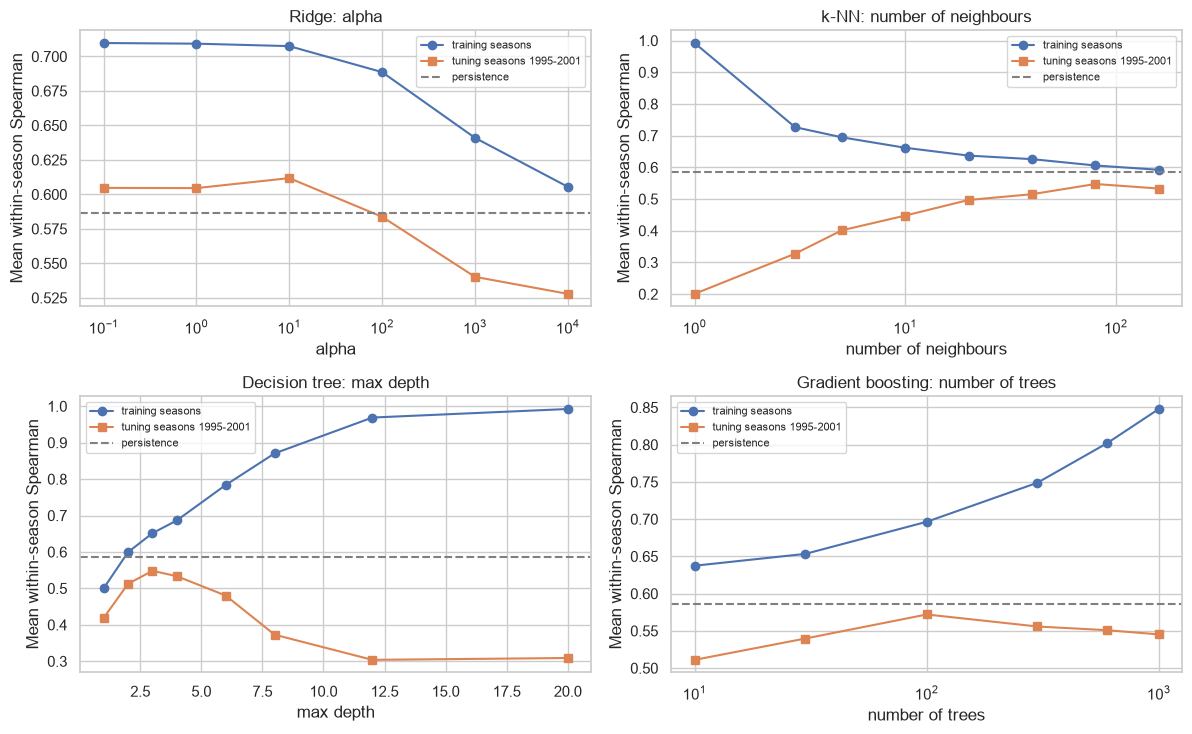

Ridge: alpha
  value  train  validation
    0.1  0.710       0.605
    1.0  0.709       0.605
   10.0  0.708       0.612
  100.0  0.689       0.584
 1000.0  0.641       0.540
10000.0  0.605       0.528 

k-NN: number of neighbours
 value  train  validation
     1  0.992       0.201
     3  0.727       0.328
     5  0.695       0.401
    10  0.662       0.448
    20  0.637       0.497
    40  0.626       0.515
    80  0.606       0.547
   160  0.592       0.533 

Decision tree: max depth
 value  train  validation
     1  0.500       0.419
     2  0.599       0.512
     3  0.651       0.548
     4  0.687       0.533
     6  0.784       0.480
     8  0.870       0.373
    12  0.969       0.304
    20  0.992       0.309 

Gradient boosting: number of trees
 value  train  validation
    10  0.637       0.511
    30  0.653       0.540
   100  0.696       0.572
   300  0.749       0.556
   600  0.802       0.551
  1000  0.848       0.545 



In [5]:
def validation_curve(name, param, values, fixed=None):
    rows = []
    for v in values:
        params = dict(best_params[name])
        params.update(fixed or {})
        params[param] = v
        scores, _ = evaluate(build(name, params), TUNE)
        rows.append({'value': v, 'train': scores['train_spearman'].mean(), 'validation': scores['spearman'].mean()})
    return pd.DataFrame(rows)


curves = {
    'Ridge: alpha': validation_curve('Ridge', 'alpha', [0.1, 1, 10, 100, 1000, 10000]),
    'k-NN: number of neighbours': validation_curve('KNN', 'n_neighbors', [1, 3, 5, 10, 20, 40, 80, 160], {'weights': 'uniform'}),
    'Decision tree: max depth': validation_curve('Tree', 'max_depth', [1, 2, 3, 4, 6, 8, 12, 20], {'min_samples_leaf': 1}),
    'Gradient boosting: number of trees': validation_curve('Gradient boosting', 'n_estimators', [10, 30, 100, 300, 600, 1000]),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (title, c) in zip(axes.ravel(), curves.items()):
    ax.plot(c['value'].astype(float), c['train'], 'o-', label='training seasons')
    ax.plot(c['value'].astype(float), c['validation'], 's-', label='tuning seasons 1995-2001')
    ax.axhline(persistence_tune, color='grey', ls='--', label='persistence')
    if not title.startswith('Decision tree'):
        ax.set_xscale('log')
    ax.set(title=title, xlabel=title.split(': ')[1], ylabel='Mean within-season Spearman')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for title, c in curves.items():
    print(title)
    print(c.round(3).to_string(index=False), '\n')

**What we found:**
- **Ridge alpha:** the training score falls from 0.710 (alpha 0.1) to 0.605 (alpha 10,000). The validation score is flat at 0.605 for small alpha, peaks at 0.612 for alpha = 10 and drops to 0.528. A small penalty steadies the correlated features; a large one underfits, shrinking the coefficients until training and validation meet.
- **k-NN neighbours (uniform weights):** with k = 1 the training score is 0.992 and the validation score only 0.201, a clear case of overfitting. Validation improves up to k = 80 (0.547) and drops at k = 160 (0.533), where the average becomes too smooth. Even the best k stays below persistence (0.586).
- **Tree depth (leaves of any size):** training rises from 0.500 (depth 1) to 0.992 (depth 20). Validation peaks at depth 3 (0.548) and falls to about 0.30 for depths 12 and 20. Depth 1 underfits (training 0.500, validation 0.419), deep trees overfit.
- **Boosting trees:** training rises from 0.637 (10 trees) to 0.848 (1,000 trees); validation peaks at 100 trees (0.572) and slowly declines to 0.545. With a small learning rate boosting overfits slowly.

**Interpretation:** the best value lies inside each curve, so the grids are wide enough. All four curves show the same picture: simple models leave signal unused and flexible ones fit the luck of past seasons, and the possible gain is small because the signal itself is weak.

## 5. Comparison on the evaluation seasons 2002-2008

Each algorithm is now fixed at its best parameters from section 4. For each evaluation season we train on all earlier seasons (which now include the tuning seasons) and predict it. We report the mean and the standard deviation over the six seasons of the four metrics, for the nine models and the three baselines.

These seasons played no role in any choice, so the comparison is fair. Six seasons is a small sample, so the next subsections look at the seasons one by one and test whether the differences are real.

In [6]:
eval_scores, eval_preds = {}, {}
for name in ALGORITHMS:
    eval_scores[name], eval_preds[name] = evaluate(build(name, best_params[name]), EVAL)
eval_rows = df.index[df['year'].isin(EVAL)]
for b in BASELINES:
    eval_scores[b] = base_scores[(base_scores['baseline'] == b) & (base_scores['folds'] == 'evaluation')].set_index('season')
    eval_preds[b] = base_preds.loc[eval_rows, b]

METRICS = ['spearman', 'pair_acc', 'rank_err', 'mae']


def mean_sd(scores):
    # "mean ± sd over seasons" for each metric
    return {m: f"{scores[m].mean():.3f} ± {scores[m].std():.3f}" for m in METRICS}


comparison = pd.DataFrame({name: mean_sd(s) for name, s in eval_scores.items()}).T
comparison['order'] = [eval_scores[n]['spearman'].mean() for n in comparison.index]
display(comparison.sort_values('order', ascending=False).drop(columns='order'))

,spearman,pair_acc,rank_err,mae
Random forest,0.555 ± 0.052,0.700 ± 0.018,6.383 ± 0.474,0.132 ± 0.018
Gradient boosting,0.542 ± 0.084,0.690 ± 0.036,6.456 ± 0.760,0.134 ± 0.018
Lasso,0.538 ± 0.059,0.691 ± 0.018,6.439 ± 0.383,0.137 ± 0.018
Ridge,0.535 ± 0.061,0.690 ± 0.020,6.411 ± 0.359,0.136 ± 0.018
Tree,0.532 ± 0.048,0.702 ± 0.025,6.439 ± 0.725,0.142 ± 0.019
Linear,0.531 ± 0.061,0.688 ± 0.020,6.478 ± 0.394,0.137 ± 0.019
MLP,0.528 ± 0.062,0.686 ± 0.018,6.394 ± 0.294,0.132 ± 0.019
SVR,0.525 ± 0.058,0.688 ± 0.018,6.317 ± 0.269,0.133 ± 0.023
Persistence,0.518 ± 0.045,0.684 ± 0.020,6.550 ± 0.341,0.138 ± 0.018
Regression to mean,0.518 ± 0.045,0.684 ± 0.020,6.550 ± 0.341,0.121 ± 0.015


**What we found** (mean ± standard deviation over the six evaluation seasons): the random forest has the best ranking (Spearman 0.555 ± 0.052), followed by gradient boosting 0.542 ± 0.084 (the most variable), Lasso 0.538, Ridge 0.535, tree 0.532, linear regression 0.531, MLP 0.528 and SVR 0.525. Persistence reaches 0.518 ± 0.045 and only k-NN (0.467) is clearly worse. The gains of the other models over persistence (0.006 to 0.036) are all smaller than one standard deviation over seasons (0.045 to 0.084). Pair accuracy is about 0.69-0.70 for the models (forest 0.700, tree 0.702) against 0.684 for persistence; the rank error is 6.32 (SVR) to 6.48 positions against 6.55 for persistence and 7.49 for the league average. The MAE of the models trained on raw ppg (0.132 to 0.142) is similar to persistence (0.138) and worse than regression to the mean (0.121).

**Interpretation:** no algorithm is a big improvement on persistence; the ensembles and the linear models gain a few hundredths of Spearman. The models cannot follow the era level of ppg, which section 7 addresses.

### 5.1 Season by season

Plot the Spearman of persistence and of six of the models in every evaluation season, and count in how many of the six seasons each model beats persistence.

A mean over six seasons can hide that one model wins every season by a little while another wins big once. The season-by-season view also shows whether the season matters more than the algorithm.

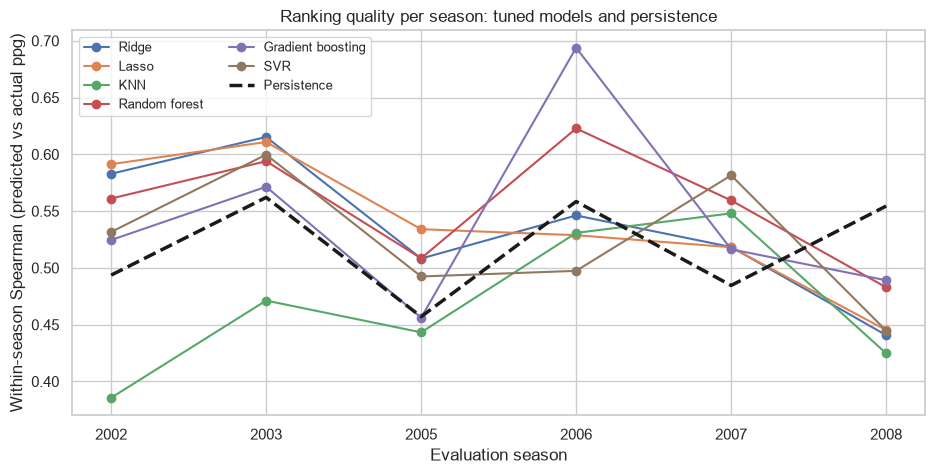

Seasons (of 6) in which the model beats persistence: {'Linear': 4, 'Ridge': 4, 'Lasso': 4, 'KNN': 1, 'Tree': 3, 'Random forest': 5, 'Gradient boosting': 4, 'SVR': 4, 'MLP': 4}


season,2002,2003,2005,2006,2007,2008
Linear,0.592,0.606,0.533,0.509,0.502,0.443
Ridge,0.583,0.615,0.508,0.546,0.518,0.441
Lasso,0.591,0.611,0.534,0.529,0.518,0.445
KNN,0.386,0.471,0.443,0.531,0.548,0.425
Tree,0.491,0.562,0.468,0.592,0.563,0.516
Random forest,0.561,0.594,0.508,0.623,0.559,0.483
Gradient boosting,0.525,0.571,0.456,0.694,0.516,0.489
SVR,0.532,0.600,0.492,0.497,0.581,0.445
MLP,0.503,0.619,0.479,0.547,0.569,0.451
Persistence,0.494,0.562,0.457,0.558,0.485,0.554


In [7]:
plt.figure(figsize=(11, 5))
labels = [str(s) for s in EVAL]
for name in ['Ridge', 'Lasso', 'KNN', 'Random forest', 'Gradient boosting', 'SVR']:
    plt.plot(labels, eval_scores[name]['spearman'].values, 'o-', label=name)
plt.plot(labels, eval_scores['Persistence']['spearman'].values, 'k--', lw=2.5, label='Persistence')
plt.xlabel('Evaluation season')
plt.ylabel('Within-season Spearman (predicted vs actual ppg)')
plt.title('Ranking quality per season: tuned models and persistence')
plt.legend(ncol=2, fontsize=9)
plt.show()

wins = {}
for name in ALGORITHMS:
    wins[name] = int((eval_scores[name]['spearman'] > eval_scores['Persistence']['spearman']).sum())
print('Seasons (of 6) in which the model beats persistence:', wins)
spearman_table = pd.DataFrame({n: eval_scores[n]['spearman'] for n in list(ALGORITHMS) + ['Persistence']}).T
display(spearman_table.round(3))

**What we found:** All models except k-NN and the tree beat persistence in at least four of the six seasons: the random forest in five, the linear models, boosting, SVR and MLP in four; the tree in three and k-NN in one. In 2003 seven models are above persistence (0.562) and the tree is equal to it; in 2008 every model is below persistence (0.554, best model the tree with 0.516). Boosting is the most erratic line, from 0.456 in 2005 (about equal to persistence) to the best value of all, 0.694, in 2006. Among the models, k-NN is the lowest in four of the six seasons.

**Interpretation:** the lines move together: the season matters more than the algorithm (2005 is hard for everyone, 2003 easy). This is why the tests in 5.2 compare the models season by season instead of pooling all teams.

### 5.2 Significance tests

A **Friedman test** checks whether the ten rankers (nine models and persistence) differ at all, with the seasons as blocks. Then **Wilcoxon signed-rank tests** compare every model with persistence, and the best model on the evaluation seasons with every other model, season by season. We add the matched-pairs rank-biserial correlation as effect size (from -1 to 1) and a Holm correction for the many comparisons.

The tests are non-parametric because six season scores cannot be checked for normality. With six seasons the smallest possible two-sided Wilcoxon p-value is 2 / 2^6 = 0.031, so the power is low: we read the p-values together with the effect sizes and the number of seasons won.

In [8]:
S = pd.DataFrame({n: eval_scores[n]['spearman'] for n in list(ALGORITHMS) + ['Persistence']})
friedman = stats.friedmanchisquare(*[S[n] for n in S.columns])
print(f"Friedman test, {S.shape[1]} rankers and {S.shape[0]} seasons: chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.4f}")
print('Mean rank per ranker (1 = best, averaged over seasons):')
print(S.rank(axis=1, ascending=False).mean().sort_values().round(2).to_string())


def rank_biserial(diff):
    # Effect size of the Wilcoxon test: (sum of ranks of positive differences - negative ones) / sum of all ranks
    diff = diff[diff != 0]
    ranks = stats.rankdata(np.abs(diff))
    return (ranks[diff > 0].sum() - ranks[diff < 0].sum()) / ranks.sum()


def compare(a, b):
    diff = (S[a] - S[b]).values
    return {'mean diff': diff.mean(), 'seasons won (of 6)': (diff > 0).sum(),
            'p (Wilcoxon)': stats.wilcoxon(diff).pvalue, 'effect (rank-biserial)': rank_biserial(diff)}


vs_persistence = pd.DataFrame({n: compare(n, 'Persistence') for n in ALGORITHMS}).T.astype(float)
vs_persistence['p (Holm)'] = multipletests(vs_persistence['p (Wilcoxon)'], method='holm')[1]
print('\nEach model versus persistence:')
display(vs_persistence.round(3))

best_eval = S.mean().drop('Persistence').idxmax()
others = [n for n in S.columns if n != best_eval]
vs_best = pd.DataFrame({n: compare(best_eval, n) for n in others}).T.astype(float)
vs_best['p (Holm)'] = multipletests(vs_best['p (Wilcoxon)'], method='holm')[1]
print(f'{best_eval} (best mean on the evaluation seasons) versus each other ranker:')
display(vs_best.round(3))

Friedman test, 10 rankers and 6 seasons: chi2 = 10.76, p = 0.2923
Mean rank per ranker (1 = best, averaged over seasons):
Random forest        3.83
MLP                  4.33
Lasso                4.50
Ridge                5.00
SVR                  5.50
Tree                 5.50
Linear               5.50
Gradient boosting    5.67
Persistence          6.50
KNN                  8.67

Each model versus persistence:


,mean diff,seasons won (of 6),p (Wilcoxon),effect (rank-biserial),p (Holm)
Linear,0.012,4.0,0.844,0.143,1.0
Ridge,0.017,4.0,0.562,0.333,1.0
Lasso,0.020,4.0,0.562,0.333,1.0
KNN,-0.051,1.0,0.156,-0.714,1.0
Tree,0.014,3.0,0.688,0.238,1.0
Random forest,0.036,5.0,0.312,0.524,1.0
Gradient boosting,0.024,4.0,0.438,0.429,1.0
SVR,0.006,4.0,1.000,0.048,1.0
MLP,0.010,4.0,0.688,0.238,1.0


Random forest (best mean on the evaluation seasons) versus each other ranker:


,mean diff,seasons won (of 6),p (Wilcoxon),effect (rank-biserial),p (Holm)
Linear,0.024,3.0,0.438,0.429,1.000
Ridge,0.019,4.0,0.312,0.524,1.000
Lasso,0.017,3.0,0.438,0.429,1.000
KNN,0.087,6.0,0.031,1.000,0.281
Tree,0.023,4.0,0.312,0.524,1.000
Gradient boosting,0.013,4.0,0.562,0.333,1.000
SVR,0.030,4.0,0.219,0.619,1.000
MLP,0.027,4.0,0.156,0.714,1.000
Persistence,0.036,5.0,0.312,0.524,1.000


**What we found:** The Friedman test over 10 rankers and 6 seasons gives chi-square = 10.76, p = 0.29: no evidence that the rankers differ. Mean ranks are best for the random forest (3.83), MLP (4.33) and Lasso (4.50), with persistence at 6.50 and k-NN last (8.67). Against persistence, the random forest gains +0.036 (wins 5 of 6 seasons, p = 0.31, rank-biserial effect 0.52), boosting +0.024 (4 of 6, p = 0.44, effect 0.43) and Lasso +0.020 (4 of 6, p = 0.56, effect 0.33); none is significant and every Holm-corrected p-value is 1.0. The random forest beats k-NN in all six seasons (p = 0.031, the smallest possible value, effect 1.0), but not after the Holm correction (p = 0.28); its differences to all other models have p between 0.16 and 0.56.

**Interpretation:** a significant result with six seasons would need a model that wins every season. The medium effect sizes of the ensembles (0.52 and 0.43) suggest a small real gain over persistence that this few seasons cannot confirm.

### 5.3 Bootstrap interval of the gain over persistence

For four models we resample the teams of each evaluation season with replacement (1,000 times), recompute the Spearman of the model and of persistence, and take the 2.5% and 97.5% percentiles of the mean difference.

The tests above only use six numbers per model. The bootstrap gives an interval for the size of the gain, which is what G1 asks about (+0.03). It only covers the variation between teams inside a season, not between seasons, so it is rather too narrow than too wide.

In [9]:
def bootstrap_diff(pred_a, pred_b, seasons, repeats=1000):
    # 95% interval of the mean (over seasons) Spearman difference between two predictions, resampling teams
    rng = np.random.default_rng(SEED)
    data = []
    for s in seasons:
        idx = df.index[df['year'] == s]
        data.append((df.loc[idx, 'target_ppg'].values, pred_a.loc[idx].values, pred_b.loc[idx].values))
    diffs = []
    for _ in range(repeats):
        d = []
        for y, a, b in data:
            i = rng.integers(0, len(y), len(y))
            d.append(stats.spearmanr(a[i], y[i])[0] - stats.spearmanr(b[i], y[i])[0])
        diffs.append(np.nanmean(d))
    return np.percentile(diffs, [2.5, 97.5])


rows = []
for name in ['Ridge', 'Lasso', 'Gradient boosting', 'Random forest']:
    low, high = bootstrap_diff(eval_preds[name], eval_preds['Persistence'], EVAL)
    rows.append({'model': name, 'mean diff vs persistence': S[name].mean() - S['Persistence'].mean(), 'CI low': low, 'CI high': high})
display(pd.DataFrame(rows).set_index('model').round(3))

,mean diff vs persistence,CI low,CI high
model,,,
Ridge,0.017,-0.061,0.103
Lasso,0.020,-0.061,0.105
Gradient boosting,0.024,-0.031,0.075
Random forest,0.036,-0.026,0.100


**What we found:** The 95% bootstrap intervals of the gain over persistence are [-0.026, 0.100] for the random forest (mean +0.036), [-0.031, 0.075] for boosting (+0.024), [-0.061, 0.105] for Lasso (+0.020) and [-0.061, 0.103] for Ridge (+0.017). All intervals contain zero, in line with the tests.

**Interpretation:** the upper ends (up to about 0.10) show that a gain of the size asked in G1 (+0.03) is plausible, and the lower ends that a loss of up to 0.06 cannot be excluded.

**Decision:** we report the ranking gain as small and not statistically established. The model is still chosen on the tuning seasons (section 7), not as the "best on the evaluation seasons", because that would reuse the evaluation seasons for a choice.

## 6. Overfitting analysis

Compare, for each tuned model, the Spearman on its training seasons with the Spearman on the evaluation seasons.

A big gap between the two means the model memorises past seasons. A small training score with a small gap means the model cannot fit even the training data well: then the limit is noise, not overfitting.

,train,evaluation,gap
Linear,0.696,0.531,0.165
Ridge,0.692,0.535,0.156
Lasso,0.694,0.538,0.156
KNN,0.993,0.467,0.526
Tree,0.639,0.532,0.107
Random forest,0.788,0.555,0.233
Gradient boosting,0.674,0.542,0.132
SVR,0.694,0.525,0.170
MLP,0.693,0.528,0.166


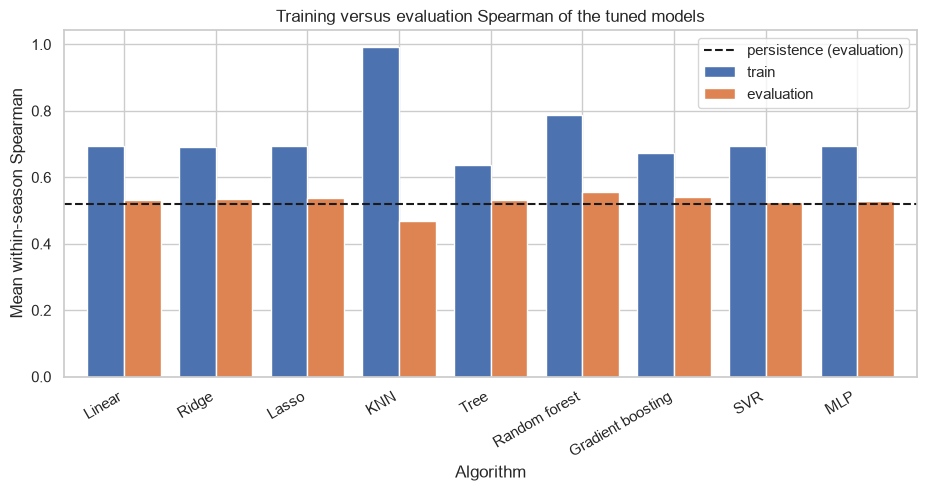

In [10]:
gap = pd.DataFrame({n: {'train': eval_scores[n]['train_spearman'].mean(), 'evaluation': eval_scores[n]['spearman'].mean()}
                    for n in ALGORITHMS}).T
gap['gap'] = gap['train'] - gap['evaluation']
display(gap.round(3))
ax = gap[['train', 'evaluation']].plot.bar(figsize=(11, 4.5), width=0.8)
ax.axhline(eval_scores['Persistence']['spearman'].mean(), color='k', ls='--', label='persistence (evaluation)')
ax.set(title='Training versus evaluation Spearman of the tuned models', xlabel='Algorithm', ylabel='Mean within-season Spearman')
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.show()

**What we found:** The gap between training and evaluation Spearman is smallest for the tree (0.107) and boosting (0.132), around 0.16-0.17 for the linear models, SVR and MLP (training about 0.69, evaluation 0.525 to 0.538), 0.233 for the random forest and 0.526 for k-NN (training 0.993, evaluation 0.467).

**Interpretation:** a large gap does not always mean a bad model: the forest has the largest gap of the good models and still the best evaluation score (0.555), because averaging many trees controls their variance. k-NN has both the largest gap and the worst score: it memorises and does not generalise. Even the linear models reach only about 0.69 on their own training seasons, so most of the season-to-season variation (injuries, trades, bounces) is not explained by any feature; their gap of about 0.16 is mostly this noise, not flexibility.

### 6.1 Learning curve

For the best model on the tuning seasons we limit the training history to the last *k* calendar years (3, 5, 8, 12, 16, 24, 32, or all seasons from 1967) and record the training and evaluation scores.

If the evaluation score still rises with more history, more data helps; if it is flat, the limit is the noise in the data. The evaluation seasons are only used as a diagnostic here: no choice is made from this curve. (Because 2004 is missing, a window that crosses it holds one season less.)

Learning curve of Lasso (best single model on the tuning seasons)
years of history  train  evaluation
               3  0.758       0.443
               5  0.717       0.491
               8  0.684       0.480
              12  0.657       0.504
              16  0.634       0.492
              24  0.643       0.501
              32  0.684       0.515
             all  0.694       0.538


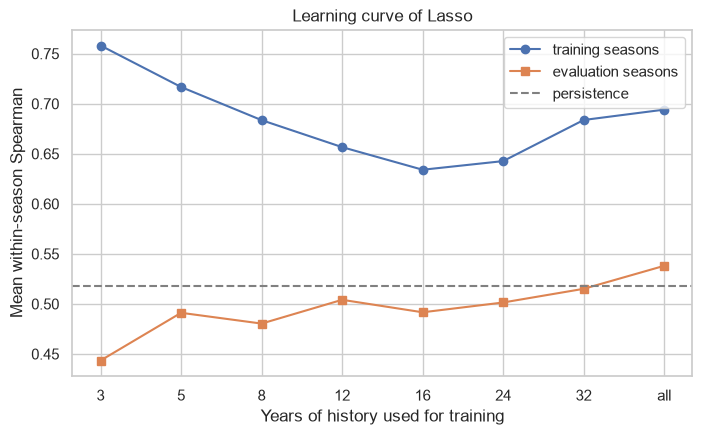

In [11]:
best_single = tuning['tuned Spearman'].idxmax()
model = build(best_single, best_params[best_single])
rows = []
for k in [3, 5, 8, 12, 16, 24, 32, None]:
    train_rho, eval_rho = [], []
    for s in EVAL:
        first = 1967 if k is None else s - k
        scores, _ = fit_predict(model, s, first_year=first)
        train_rho.append(scores['train_spearman'])
        eval_rho.append(scores['spearman'])
    rows.append({'years of history': 'all' if k is None else k, 'train': np.mean(train_rho), 'evaluation': np.mean(eval_rho)})
learning = pd.DataFrame(rows)
print(f'Learning curve of {best_single} (best single model on the tuning seasons)')
print(learning.round(3).to_string(index=False))

x = list(range(len(learning)))
plt.figure(figsize=(8, 4.5))
plt.plot(x, learning['train'], 'o-', label='training seasons')
plt.plot(x, learning['evaluation'], 's-', label='evaluation seasons')
plt.axhline(eval_scores['Persistence']['spearman'].mean(), color='grey', ls='--', label='persistence')
plt.xticks(x, learning['years of history'].astype(str))
plt.xlabel('Years of history used for training')
plt.ylabel('Mean within-season Spearman')
plt.title(f'Learning curve of {best_single}')
plt.legend()
plt.show()

**What we found:** With only the last 3 years of history the Lasso reaches 0.443 on the evaluation seasons, with 5 years 0.491, 12 years 0.504, 24 years 0.501, 32 years 0.515 and with all history since 1967 0.538. The training score is high for tiny windows (0.758 with 3 years: the model memorises them), falls to 0.634 with 16 years and rises again to 0.694 with all seasons.

**Interpretation:** the evaluation score is still rising at the end, and only the full history beats persistence (0.518). The model is limited by variance (too few seasons) more than by its form, which agrees with notebook 1 (old seasons are not outdated). More seasons or better features, not a more complex model, are the way forward (notebook 4).

## 7. Model improvement

Improve the best model step by step, each step answering a weakness seen so far:

1. **Defaults:** the best algorithm with scikit-learn default parameters.
2. **Tuned:** the parameters from section 4.
3. **Target transformation:** section 5 shows that models trained on raw ppg have a large MAE, because the league level of ppg changes with the era. We train on the within-season z-score of ppg instead (parameters re-tuned for this target) and convert back with the league mean and spread of the last training season.
4. **Ensemble:** average the predictions of the best algorithm of each of the three best families (voting regressor). Different kinds of models make different errors, and averaging cancels part of them. We try it with both targets.

**Rule for choosing a step, fixed before running it:** only the tuning seasons count. Among the steps whose tuning Spearman is within 0.005 of the best step, we take the one with the lowest tuning MAE (the ranking is the goal, the level breaks ties). The evaluation seasons are shown but play no role. The G1 goal on the tuning seasons is persistence + 0.03.

In [12]:
# Best algorithm of each family on the tuning seasons, then the three best of these
families = {'linear': ['Linear', 'Ridge', 'Lasso'], 'instance-based': ['KNN'], 'single tree': ['Tree'],
            'tree ensembles': ['Random forest', 'Gradient boosting'], 'kernel and neural': ['SVR', 'MLP']}
best_of_family = []
for family, names in families.items():
    best_of_family.append(tuning.loc[names, 'tuned Spearman'].idxmax())
top3 = tuning.loc[best_of_family, 'tuned Spearman'].sort_values(ascending=False).index[:3].tolist()
print('Ensemble members (best of the three best families):', top3)

z_params = tune(best_single, 'target_ppg_z').loc[0, 'params']
print(f'{best_single} parameters re-tuned for the z-score target:', z_params)
ensemble = VotingRegressor([(n, build(n, best_params[n])) for n in top3])
steps = {
    '1 defaults': (build(best_single), 'target_ppg'),
    '2 tuned': (build(best_single, best_params[best_single]), 'target_ppg'),
    '3 tuned + z target': (build(best_single, z_params), 'target_ppg_z'),
    '4a ensemble, ppg target': (ensemble, 'target_ppg'),
    '4b ensemble, z target': (ensemble, 'target_ppg_z'),
}
rows, step_preds = [], {}
for step, (model, target) in steps.items():
    t, _ = evaluate(model, TUNE, target)
    e, p = evaluate(model, EVAL, target)
    step_preds[step] = (e, p)
    rows.append({'step': step, 'tune Spearman': t['spearman'].mean(), 'tune MAE': t['mae'].mean(),
                 'eval Spearman': e['spearman'].mean(), 'eval MAE': e['mae'].mean(), 'eval rank error': e['rank_err'].mean()})
steps_table = pd.DataFrame(rows).set_index('step')
goal = persistence_tune + 0.03
steps_table['gap to goal (tune)'] = steps_table['tune Spearman'] - goal
print(f'G1 goal on the tuning seasons: {goal:.3f}')
display(steps_table.round(3))

# The rule stated above
close = steps_table[steps_table['tune Spearman'] >= steps_table['tune Spearman'].max() - 0.005]
final_step = close['tune MAE'].idxmin()
print('Chosen step:', final_step)

Ensemble members (best of the three best families): ['Lasso', 'SVR', 'Random forest']


Lasso parameters re-tuned for the z-score target: {'alpha': 0.001}


G1 goal on the tuning seasons: 0.616


,tune Spearman,tune MAE,eval Spearman,eval MAE,eval rank error,gap to goal (tune)
step,,,,,,
1 defaults,NaN,0.161,NaN,0.168,7.489,NaN
2 tuned,0.615,0.127,0.538,0.137,6.439,-0.001
3 tuned + z target,0.615,0.120,0.545,0.118,6.344,-0.001
"4a ensemble, ppg target",0.605,0.124,0.540,0.130,6.328,-0.011
"4b ensemble, z target",0.592,0.122,0.555,0.117,6.328,-0.025


Chosen step: 3 tuned + z target


**What we found** (persistence on the tuning seasons 0.586, so the G1 goal there is 0.616):
- **Step 1, defaults:** the default Lasso predicts a constant (Spearman undefined, tuning MAE 0.161), so step 2 is the difference between no model and a model.
- **Step 2, tuned:** Spearman 0.615 (gap to the goal -0.001), MAE 0.127.
- **Step 3, z-score target** (Lasso re-tuned for the new target, alpha = 0.001): the same Spearman 0.615 and a clearly lower MAE, 0.120 on the tuning seasons (0.118 on the evaluation seasons, against 0.137 for step 2). The z-score removes the era level of ppg and the conversion back uses the latest league level.
- **Step 4, ensemble** of Lasso, SVR and random forest (the best of the three best families): 0.605 with the ppg target and 0.592 with the z target on the tuning seasons, worse than step 3 because the non-linear members are weaker there.
- On the evaluation seasons, which played no role, the steps reach 0.538, 0.545, 0.540 and 0.555 (4b). The ensemble with z target would look best there, but it loses on the tuning seasons, so the rule rejects it.

**Decision:** step 3, Lasso (alpha = 0.001) on the within-season z-score of ppg. It is as good as the best step in Spearman and has the lowest MAE. On the tuning seasons it is 0.001 short of the G1 goal (0.615 vs 0.616).

### 7.1 The chosen model against persistence

Compare the chosen model with persistence on the evaluation seasons: Spearman per season, Wilcoxon test with effect size, bootstrap interval of the gain, and the four metrics next to the three baselines.

This is the answer to G1 on seasons that were not used for any choice.

In [13]:
final_model, final_target = steps[final_step]
final_scores, final_pred = step_preds[final_step]
eval_scores['Final model'], eval_preds['Final model'] = final_scores, final_pred

display(pd.DataFrame({'Final model': final_scores['spearman'], 'Persistence': eval_scores['Persistence']['spearman']}).T.round(3))
diff = (final_scores['spearman'] - eval_scores['Persistence']['spearman']).values
print(f"Evaluation Spearman {final_scores['spearman'].mean():.3f} vs persistence {eval_scores['Persistence']['spearman'].mean():.3f}; "
      f"wins {(diff > 0).sum()} of {len(diff)} seasons")
print(f"Wilcoxon p = {stats.wilcoxon(diff).pvalue:.3f}, rank-biserial = {rank_biserial(diff):.2f}")
low, high = bootstrap_diff(final_pred, eval_preds['Persistence'], EVAL)
print(f'Bootstrap 95% interval of the difference: [{low:.3f}, {high:.3f}]')
display(pd.DataFrame({n: mean_sd(eval_scores[n]) for n in ['Persistence', 'Regression to mean', 'League average', 'Final model']}).T)

season,2002,2003,2005,2006,2007,2008
Final model,0.590,0.654,0.512,0.544,0.522,0.451
Persistence,0.494,0.562,0.457,0.558,0.485,0.554


Evaluation Spearman 0.545 vs persistence 0.518; wins 4 of 6 seasons
Wilcoxon p = 0.562, rank-biserial = 0.33


Bootstrap 95% interval of the difference: [-0.049, 0.102]


,spearman,pair_acc,rank_err,mae
Persistence,0.518 ± 0.045,0.684 ± 0.020,6.550 ± 0.341,0.138 ± 0.018
Regression to mean,0.518 ± 0.045,0.684 ± 0.020,6.550 ± 0.341,0.121 ± 0.015
League average,nan ± nan,nan ± nan,7.489 ± 0.017,0.148 ± 0.028
Final model,0.545 ± 0.070,0.695 ± 0.023,6.344 ± 0.438,0.118 ± 0.012


**What we found:** The chosen model reaches a mean Spearman of 0.545 ± 0.070 on the evaluation seasons against 0.518 ± 0.045 for persistence (+0.027, just below the G1 goal of +0.03). It wins four of the six seasons (2002 0.590 vs 0.494, 2003 0.654 vs 0.562, 2005 0.512 vs 0.457, 2007 0.522 vs 0.485) and loses two (2006 0.544 vs 0.558, 2008 0.451 vs 0.554). The Wilcoxon test gives p = 0.56 with effect size 0.33, and the bootstrap interval of the gain is [-0.049, 0.102]: positive on average, not significant. Pair accuracy is 0.695 vs 0.684 and the rank error 6.34 vs 6.55 positions. The clear gain is in the level: MAE 0.118 ± 0.012, against 0.138 for persistence and 0.121 for regression to the mean.

**Decision:** the final model is the Lasso on the z-score target. G1 is partly met: the model beats persistence in more than half of the seasons and by 0.027 on average, but not by 0.03 and not significantly.

## 8. Feature importance

**Permutation importance** of the final model on the evaluation seasons: in each season we shuffle one feature among the teams (10 times), predict again and record how much the Spearman drops. We do the same for groups of related features, because correlated features share their importance when shuffled one at a time. We also show the **Ridge coefficients** (features are standardised, so they are comparable), averaged over the six evaluation folds.

Permutation importance works for any model and uses our own metric. Ridge coefficients show the direction of each effect, which permutation does not. If the two methods agree, the story is stable.

In [14]:
GROUPS = {
    'Offence (goals for, power play, shooting %)': ['prev_gf_pg_z', 'prev_pp_pct_z', 'prev_shooting_pct_z', 'prev_top_scorer_share_z'],
    'Defence and goaltending (goals against, penalty kill, save %)': ['prev_ga_pg_z', 'prev_pk_pct_z', 'prev_save_pct_z',
                                                                      'prev_starter_minutes_share_z', 'prev_goalie_data_missing'],
    'Luck (luck, PDO)': ['prev_luck_z', 'prev_pdo_z'],
    'Discipline and special teams (PIM, shorthanded)': ['prev_pim_pg_z', 'prev_shorthanded_net_pg_z'],
    'Form and venue (home edge, late form)': ['prev_home_edge_z', 'prev_late_form_z'],
    'Playoffs': ['prev_made_playoffs', 'prev_playoff_series_won_z'],
    'Roster (players used, age)': ['prev_players_used_z', 'prev_roster_age_z'],
    'Coach': ['coach_new', 'coach_tenure', 'coach_career_games_log', 'coach_career_pct', 'prev_coach_change', 'coach_first_time'],
    'Season type': ['prev_short_season', 'has_prev'],
}
grouped = [f for cols in GROUPS.values() for f in cols]
assert sorted(grouped) == sorted(FEATURES)   # every feature is in exactly one group


def permutation_drops(model, target, season, repeats=10):
    # Drop in Spearman when one feature (or group) is shuffled among the teams of the season
    rng = np.random.default_rng(SEED + season)
    train, test = df[df['year'] < season], df[df['year'] == season]
    fitted = clone(model).fit(train[FEATURES], train[target])
    base = stats.spearmanr(fitted.predict(test[FEATURES]), test['target_ppg'])[0]
    units = {f: [f] for f in FEATURES}
    units.update(GROUPS)
    drops = {}
    for unit, cols in units.items():
        d = []
        for _ in range(repeats):
            X = test[FEATURES].copy()
            X[cols] = X[cols].values[rng.permutation(len(X))]
            d.append(base - stats.spearmanr(fitted.predict(X), test['target_ppg'])[0])
        drops[unit] = np.mean(d)
    return drops


perm = pd.DataFrame({s: permutation_drops(final_model, final_target, s) for s in EVAL}).T
importance = pd.DataFrame({'mean drop': perm.mean(), 'sd over seasons': perm.std(), 'seasons with drop > 0': (perm > 0).sum()})

# Ridge coefficients in each evaluation fold
coefs = {}
for s in EVAL:
    train = df[df['year'] < s]
    ridge = build('Ridge', best_params['Ridge']).fit(train[FEATURES], train['target_ppg'])
    coefs[s] = pd.Series(ridge[-1].coef_, index=FEATURES)
coefs = pd.DataFrame(coefs)
coef_mean = coefs.mean(axis=1)
same_sign = (np.sign(coefs).eq(np.sign(coef_mean), axis=0)).sum(axis=1)

top = importance.loc[FEATURES].sort_values('mean drop', ascending=False).head(12)
print('Permutation importance of single features (drop in Spearman, top 12):')
display(top.round(4))
print('Permutation importance of feature groups:')
display(importance.loc[list(GROUPS)].sort_values('mean drop', ascending=False).round(4))
print('Ridge coefficients (ppg per 1 SD), mean over the evaluation folds, and folds with the same sign:')
ridge_table = pd.DataFrame({'mean coef': coef_mean, 'same sign in folds': same_sign})
display(ridge_table.loc[coef_mean.abs().sort_values(ascending=False).index].head(12).round(4))

Permutation importance of single features (drop in Spearman, top 12):


,mean drop,sd over seasons,seasons with drop > 0
prev_ga_pg_z,0.4121,0.0429,6
prev_gf_pg_z,0.3169,0.1396,6
prev_pdo_z,0.0875,0.0597,6
prev_shooting_pct_z,0.0564,0.0602,5
prev_save_pct_z,0.0402,0.0340,5
prev_coach_change,0.0142,0.0173,5
prev_roster_age_z,0.0141,0.0230,4
coach_first_time,0.0108,0.0108,5
prev_pk_pct_z,0.0085,0.0278,4
prev_playoff_series_won_z,0.0083,0.0145,5


Permutation importance of feature groups:


,mean drop,sd over seasons,seasons with drop > 0
"Defence and goaltending (goals against, penalty kill, save %)",0.4951,0.0331,6
"Offence (goals for, power play, shooting %)",0.3897,0.1350,6
"Luck (luck, PDO)",0.0588,0.0855,5
"Roster (players used, age)",0.0136,0.0286,4
Coach,0.0090,0.0269,4
Playoffs,0.0033,0.0059,4
"Discipline and special teams (PIM, shorthanded)",0.0013,0.0132,3
Season type,0.0000,0.0000,0
"Form and venue (home edge, late form)",-0.0007,0.0106,3


Ridge coefficients (ppg per 1 SD), mean over the evaluation folds, and folds with the same sign:


,mean coef,same sign in folds
prev_ga_pg_z,-0.1138,6
prev_gf_pg_z,0.0943,6
prev_pdo_z,-0.0560,6
has_prev,0.0467,6
prev_shooting_pct_z,0.0231,6
coach_first_time,0.0197,6
prev_made_playoffs,-0.0188,6
coach_career_pct,0.0186,6
prev_playoff_series_won_z,0.0183,6
prev_roster_age_z,-0.0176,6


**What we found** (permutation importance on the evaluation seasons, drop in Spearman):
- **Goals against** is by far the most important feature (0.412, a drop in all six seasons), then **goals for** (0.317, but variable, SD 0.140). PDO (0.088, six of six seasons), shooting percentage (0.056) and save percentage (0.040) follow; every other feature drops the Spearman by less than 0.015.
- **By group:** defence and goaltending 0.495, offence 0.390, luck (luck and PDO) 0.059, roster 0.014, coach 0.009, playoffs 0.003, and about zero for discipline, form and venue, and season type. Groups add up to more than their single features because correlated features share their importance when shuffled alone.
- **Ridge coefficients** (ppg per 1 SD, mean over the six evaluation folds, same sign in all six folds for the twelve largest): goals against -0.114, goals for +0.094, PDO -0.056, has_prev +0.047, shooting percentage +0.023, first-time coach +0.020, made playoffs -0.019, coach career points share +0.019, playoff series won +0.018, roster age -0.018, coach change last season +0.016, penalty kill +0.013.

**Interpretation:** last season's goal difference is the backbone of the prediction, with the defensive side (including goaltending) weighing more: one SD better defence is worth about 0.11 ppg, roughly 9 points over 82 games, and one SD better offence about 0.09 ppg (about 8 points). PDO has a negative coefficient (about -0.056 ppg, -4.6 points per SD): teams that were lucky in shooting and saving last year are expected to fall back, the regression to the mean of notebook 1. Shooting percentage alone is positive because part of it is real skill. The luck feature itself has almost no weight because PDO carries the same information. The coach features have small, stable signs, but their group importance (0.009) is within the noise between seasons. has_prev marks the 25 expansion-team rows of the early years and plays no role in 2009; made playoffs (negative) and playoff series won (positive) share their effect and should not be read separately.

### 8.1 The three views side by side

One figure with the group importance, the top single features and the largest Ridge coefficients, so the two methods can be compared at a glance.

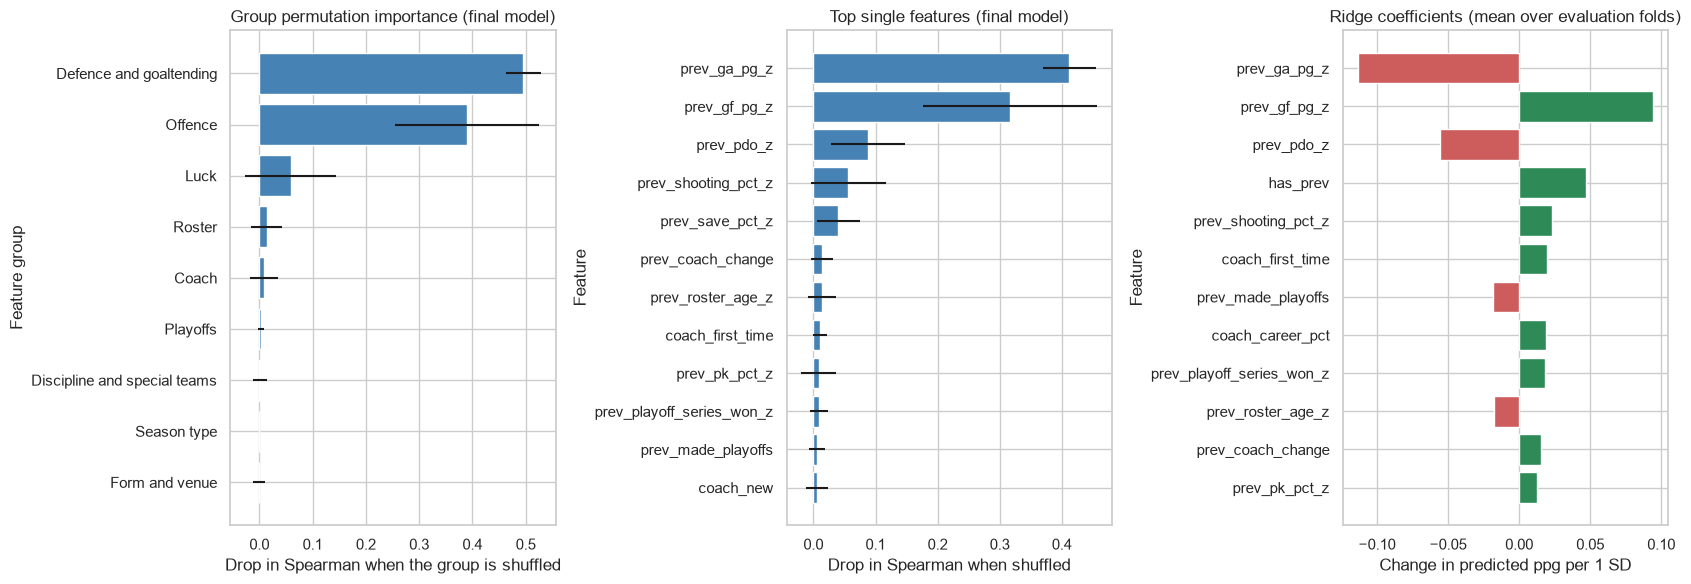

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 6))
g = importance.loc[list(GROUPS)].sort_values('mean drop')
ax[0].barh([s.split(' (')[0] for s in g.index], g['mean drop'], xerr=g['sd over seasons'], color='steelblue')
ax[0].set(title='Group permutation importance (final model)', xlabel='Drop in Spearman when the group is shuffled', ylabel='Feature group')
t = top.iloc[::-1]
ax[1].barh(t.index, t['mean drop'], xerr=t['sd over seasons'], color='steelblue')
ax[1].set(title='Top single features (final model)', xlabel='Drop in Spearman when shuffled', ylabel='Feature')
c = coef_mean.loc[coef_mean.abs().sort_values().index].tail(12)
ax[2].barh(c.index, c.values, color=np.where(c.values > 0, 'seagreen', 'indianred'))
ax[2].set(title='Ridge coefficients (mean over evaluation folds)', xlabel='Change in predicted ppg per 1 SD', ylabel='Feature')
plt.tight_layout()
plt.show()

**What we found:** In the group view only two bars are far from zero, defence and goaltending, and offence; luck has a smaller bar with a wide error bar (a drop in five of six seasons, with a very variable size). In the single-feature view the five goal and goaltending features dominate. The Ridge coefficients (a different model from the final Lasso) agree with the permutation ranking on the top features (goals against, goals for, PDO, shooting percentage), and their signs give the direction: goals against and PDO negative, goals for positive. Save percentage matters in the permutation view but not in the Ridge top list, because goals against already contains it.

**Interpretation:** the two methods agree on what matters, so the importance story is stable.

## 9. White-box models

Train a shallow decision tree (depth 3, at least 20 teams per leaf) on all seasons before 2009 and read its rules in hockey terms. We also score the same tree on the evaluation seasons, to see what we pay for the simplicity.

Business goal G3 asks for explanations a general manager can follow. A depth-3 tree has at most eight rules of at most three questions each. The features are z-scores inside the season, so a threshold of 0 means "league average" and 1 means "one standard deviation above average". The imputer fills the missing values; the tree itself is fitted on unscaled z-scores, so the thresholds stay readable.

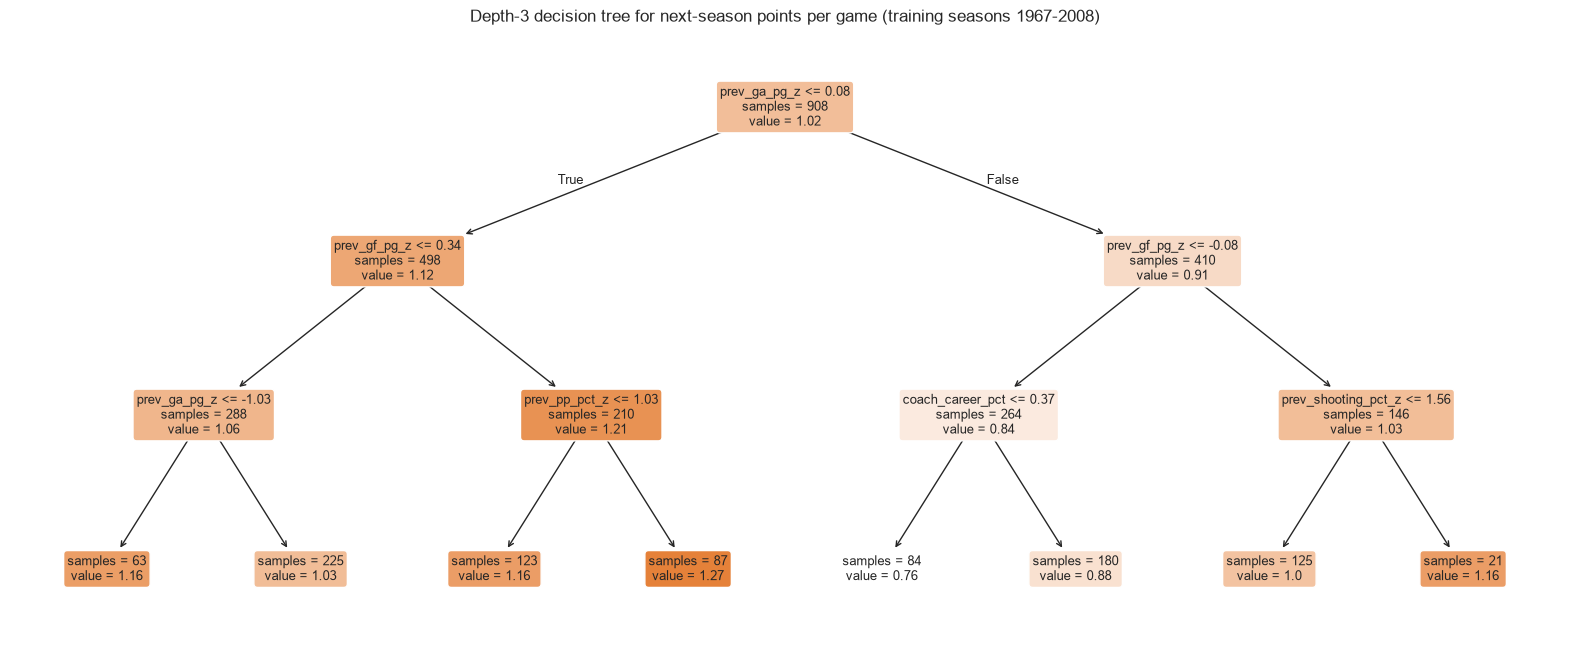

Depth-3 tree on the evaluation seasons: Spearman 0.542, MAE 0.143 (Ridge 0.535, persistence 0.518)
|--- prev_ga_pg_z <= 0.08
|   |--- prev_gf_pg_z <= 0.34
|   |   |--- prev_ga_pg_z <= -1.03
|   |   |   |--- value: [1.16]
|   |   |--- prev_ga_pg_z >  -1.03
|   |   |   |--- value: [1.03]
|   |--- prev_gf_pg_z >  0.34
|   |   |--- prev_pp_pct_z <= 1.03
|   |   |   |--- value: [1.16]
|   |   |--- prev_pp_pct_z >  1.03
|   |   |   |--- value: [1.27]
|--- prev_ga_pg_z >  0.08
|   |--- prev_gf_pg_z <= -0.08
|   |   |--- coach_career_pct <= 0.37
|   |   |   |--- value: [0.76]
|   |   |--- coach_career_pct >  0.37
|   |   |   |--- value: [0.88]
|   |--- prev_gf_pg_z >  -0.08
|   |   |--- prev_shooting_pct_z <= 1.56
|   |   |   |--- value: [1.00]
|   |   |--- prev_shooting_pct_z >  1.56
|   |   |   |--- value: [1.16]



In [16]:
train = df[df['year'] < 2009]
imputer = IterativeImputer(max_iter=10, random_state=SEED).fit(train[FEATURES])
X_train = pd.DataFrame(imputer.transform(train[FEATURES]), columns=FEATURES)
tree3 = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=SEED).fit(X_train, train['target_ppg'].values)

plt.figure(figsize=(20, 8))
plot_tree(tree3, feature_names=FEATURES, filled=True, rounded=True, precision=2, fontsize=9, impurity=False)
plt.title('Depth-3 decision tree for next-season points per game (training seasons 1967-2008)')
plt.show()

tree_scores, _ = evaluate(build('Tree', {'max_depth': 3, 'min_samples_leaf': 20}), EVAL)
print(f"Depth-3 tree on the evaluation seasons: Spearman {tree_scores['spearman'].mean():.3f}, MAE {tree_scores['mae'].mean():.3f} "
      f"(Ridge {eval_scores['Ridge']['spearman'].mean():.3f}, persistence {eval_scores['Persistence']['spearman'].mean():.3f})")
print(export_text(tree3, feature_names=FEATURES, decimals=2))

**What we found:** The tree has eight rules. The first split is on goals against (z = 0.08, about league average), the second on goals for. Reading the leaves (predicted ppg):
- Average or better defence and strong offence (goals for z > 0.34): 1.16, and 1.27 if the power play is also strong (z > 1.03). These are the best teams.
- Average or better defence and weaker offence: 1.03, and 1.16 for an elite defence (goals against z below -1.03): very good defence and goaltending carry a team even without scoring.
- Weak defence (z > 0.08) and weak offence (z <= -0.08): 0.76, and 0.88 if the coach has a career points share above 0.37. These are the worst teams, and an experienced coach is worth about 0.12 ppg here, the only place where the coach appears.
- Weak defence but average or better offence: 1.00, and 1.16 if the team shot unusually well (shooting percentage z > 1.56).

On the evaluation seasons this depth-3 tree reaches a Spearman of 0.542 (Ridge 0.535, persistence 0.518) with an MAE of 0.143.

**Interpretation:** the tree ranks as well as the linear models with only eight rules, but its level is coarse: there are only eight possible predictions, so many teams tie.

### 9.1 Ridge coefficients

Fit the tuned Ridge model on all seasons 1967-2008 and list its coefficients. A linear model is a white box too: each coefficient is the change in predicted ppg for one standard deviation more of that feature.

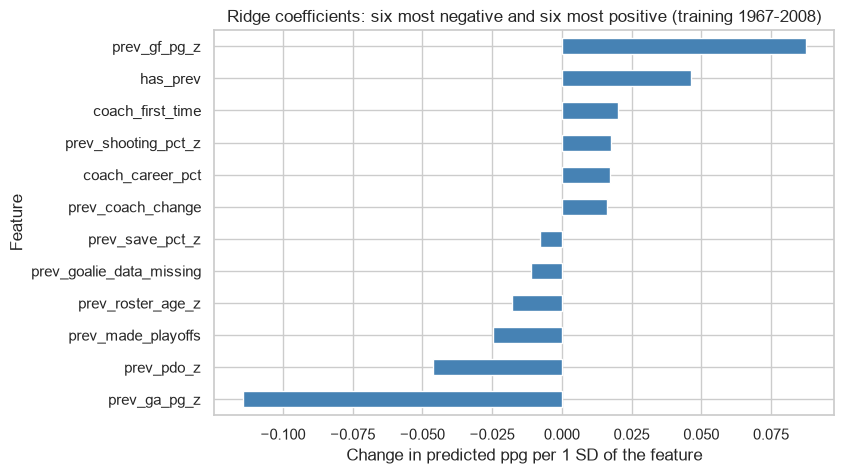

Ridge intercept 1.024, alpha 10
prev_ga_pg_z                   -0.1145
prev_pdo_z                     -0.0463
prev_made_playoffs             -0.0246
prev_roster_age_z              -0.0179
prev_goalie_data_missing       -0.0109
prev_save_pct_z                -0.0077
prev_short_season              -0.0062
prev_late_form_z               -0.0024
prev_players_used_z            -0.0017
prev_starter_minutes_share_z   -0.0014
prev_pp_pct_z                  -0.0002
prev_shorthanded_net_pg_z       0.0001
prev_pim_pg_z                   0.0027
prev_home_edge_z                0.0050
prev_luck_z                     0.0052
coach_new                       0.0055
coach_tenure                    0.0062
prev_top_scorer_share_z         0.0109
prev_pk_pct_z                   0.0115
coach_career_games_log          0.0119
prev_playoff_series_won_z       0.0148
prev_coach_change               0.0161
coach_career_pct                0.0174
prev_shooting_pct_z             0.0177
coach_first_time                

In [17]:
ridge_all = build('Ridge', best_params['Ridge']).fit(train[FEATURES], train['target_ppg'])
rc = pd.Series(ridge_all[-1].coef_, index=FEATURES).sort_values()
pd.concat([rc.head(6), rc.tail(6)]).plot.barh(figsize=(8, 5), color='steelblue')
plt.title('Ridge coefficients: six most negative and six most positive (training 1967-2008)')
plt.xlabel('Change in predicted ppg per 1 SD of the feature')
plt.ylabel('Feature')
plt.show()
print(f"Ridge intercept {ridge_all[-1].intercept_:.3f}, alpha {best_params['Ridge']['alpha']}")
print(rc.round(4).to_string())

**What we found:** The Ridge model trained on 1967-2008 has an intercept of 1.024 ppg (the average team) and four large coefficients: goals against -0.115 ppg per SD, goals for +0.088, PDO -0.046 and has_prev +0.046. No other coefficient is larger than 0.025 in absolute value: made playoffs -0.025, first-time coach +0.020, roster age -0.018, shooting percentage +0.018, coach career points share +0.017, coach change last season +0.016, playoff series won +0.015, penalty kill +0.012. Power play, short-handed goals, penalty minutes, home edge, late-season form and goalie workload are essentially zero (all below 0.006 in absolute value).

**Interpretation:** a manager can read the model as "last year's goal difference, corrected for lucky percentages, plus a little for the coach". The tree and the linear model tell the same story.

## 10. Final test on 2009

Train the chosen model on all seasons 1967-2008 and predict 2009 once. Report the four metrics against the baselines, a bootstrap interval over teams, and the full list of 30 teams with predicted and actual rank, and save the predictions to `data/processed/predictions_2009_ranking.csv`. Nothing is changed after this step.

One season of 30 teams is a small, noisy test, so it shows how the model would have served a front office before the 2009 season but cannot prove on its own that the model beats persistence; that evidence comes from the six evaluation seasons.

In [18]:
train, test = df[df['year'] < 2009], df[df['year'] == 2009].copy()
final = clone(final_model).fit(train[FEATURES], train[final_target])
pred = final.predict(test[FEATURES])
if final_target == 'target_ppg_z':
    last = df.loc[df['year'] == 2008, 'target_ppg']
    pred = pred * last.std() + last.mean()
test['pred_ppg'] = pred
test['pred_rank'] = stats.rankdata(-test['pred_ppg'], method='min').astype(int)
test['actual_rank'] = stats.rankdata(-test['target_ppg'], method='min').astype(int)
test['persistence_rank'] = stats.rankdata(-test['baseline_prev_ppg'], method='min').astype(int)
test['rank_error'] = (test['pred_rank'] - test['actual_rank']).abs()

test_base = baseline_predictions(2009)
results = {'Final model': season_metrics(test['target_ppg'], test['pred_ppg'])}
for b in BASELINES:
    results[b] = season_metrics(test['target_ppg'], test_base[b])
display(pd.DataFrame(results).T.round(3))

# Bootstrap over the 30 teams
rng = np.random.default_rng(SEED)
y, a, b = test['target_ppg'].values, test['pred_ppg'].values, test['baseline_prev_ppg'].values
boot = []
for _ in range(2000):
    i = rng.integers(0, 30, 30)
    boot.append((stats.spearmanr(a[i], y[i])[0], stats.spearmanr(b[i], y[i])[0]))
boot = np.array(boot)
print('Bootstrap 95% intervals of Spearman:',
      f"final model {np.nanpercentile(boot[:, 0], [2.5, 97.5]).round(3)}, persistence {np.nanpercentile(boot[:, 1], [2.5, 97.5]).round(3)},",
      f"difference {np.nanpercentile(boot[:, 0] - boot[:, 1], [2.5, 97.5]).round(3)}")

out = test[['year', 'tmID', 'name', 'pred_ppg', 'pred_rank', 'target_ppg', 'actual_rank', 'persistence_rank']].rename(columns={'target_ppg': 'actual_ppg'})
out.sort_values('pred_rank').to_csv(ROOT / 'data' / 'processed' / 'predictions_2009_ranking.csv', index=False)
display(test.sort_values('pred_rank')[['name', 'pred_rank', 'actual_rank', 'persistence_rank', 'pred_ppg', 'target_ppg', 'rank_error']].round(3))

,spearman,pair_acc,rank_err,mae
Final model,0.540,0.686,6.667,0.105
Persistence,0.474,0.673,6.933,0.137
Regression to mean,0.474,0.673,6.933,0.116
League average,NaN,NaN,7.467,0.125


Bootstrap 95% intervals of Spearman: final model [0.178 0.772], persistence [0.105 0.75 ], difference [-0.068  0.223]


,name,pred_rank,actual_rank,persistence_rank,pred_ppg,target_ppg,rank_error
915,Chicago Blackhawks,1,3,6,1.323,1.366,2
910,Boston Bruins,2,14,2,1.300,1.110,12
932,San Jose Sharks,3,2,1,1.297,1.378,1
918,Detroit Red Wings,4,7,3,1.271,1.244,3
931,Pittsburgh Penguins,5,8,8,1.253,1.232,3
937,Washington Capitals,6,1,4,1.233,1.476,5
925,New Jersey Devils,7,5,5,1.190,1.256,2
913,Carolina Hurricanes,8,24,11,1.184,0.976,16
936,Vancouver Canucks,9,5,7,1.171,1.256,4
922,Minnesota Wild,10,22,19,1.163,1.024,12


**What we found** (season 2009, 30 teams):
- Spearman 0.540 for the final model against 0.474 for persistence (+0.066), pair accuracy 0.686 vs 0.673, rank error 6.67 vs 6.93 positions, and MAE 0.105 vs 0.137 (regression to the mean 0.116, league average 0.125). The model beats persistence on all four metrics, but the margin in ranking is small.
- The bootstrap intervals over teams are wide: Spearman [0.178, 0.772] for the model and [0.105, 0.750] for persistence; the interval of the difference, [-0.068, 0.223], contains zero. One season cannot show that the model is better, only that it is not worse.
- Largest misses: Phoenix (predicted 25, actual 4: 21 positions), Carolina (8 vs 24), Colorado (27 vs 12), Boston (2 vs 14), Minnesota (10 vs 22), Columbus (14 vs 26), Nashville (22 vs 10) and Los Angeles (19 vs 8). Persistence made similar errors for most of them (Phoenix 25, Colorado 28, Boston 2).
- The top is largely right: Chicago, San Jose, Washington and New Jersey are predicted in the top seven and are all in the actual top five. So is the bottom: Toronto, Tampa Bay and the Islanders are predicted 26, 29 and 30 and finish 29, 24 and 26.

**Interpretation:** the teams that surprised were not unusually strong or weak on last season's numbers; what changed for them (players, goalies, coaches) is not in a table built from last season, which is the limit of this approach.

### 10.1 Predicted versus actual rank

Scatter plots of predicted against actual rank in 2009 for the final model and for persistence, with the teams that are 10 or more positions off labelled.

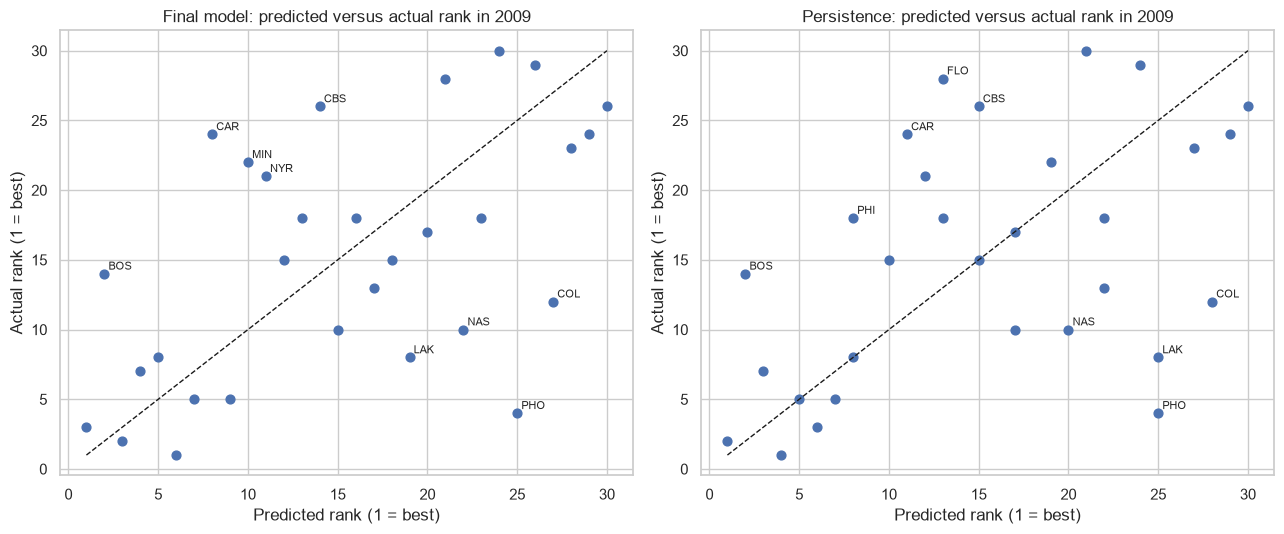

Teams 10 or more positions off: final model 9, persistence 9


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for k, (col, title) in enumerate([('pred_rank', 'Final model'), ('persistence_rank', 'Persistence')]):
    ax[k].scatter(test[col], test['actual_rank'], s=40)
    ax[k].plot([1, 30], [1, 30], 'k--', lw=1)
    for _, r in test.iterrows():
        if abs(r[col] - r['actual_rank']) >= 10:
            ax[k].annotate(r['tmID'], (r[col], r['actual_rank']), fontsize=8, xytext=(3, 3), textcoords='offset points')
    ax[k].set(title=f'{title}: predicted versus actual rank in 2009', xlabel='Predicted rank (1 = best)', ylabel='Actual rank (1 = best)')
plt.tight_layout()
plt.show()
far_model = int((test['rank_error'] >= 10).sum())
far_persistence = int(((test['persistence_rank'] - test['actual_rank']).abs() >= 10).sum())
print(f'Teams 10 or more positions off: final model {far_model}, persistence {far_persistence}')

**What we found:** Points near the diagonal are good predictions. Both methods show a similar cloud around the diagonal: nine teams are 10 or more positions off for the final model, and nine for persistence. Most large errors are shared by both (Phoenix, Boston, Carolina, Columbus, Colorado, Los Angeles, Nashville). The model avoids some persistence errors (for example Florida, 13th for persistence and actually 28th) and makes others of its own (Minnesota and the Rangers, predicted 10th and 11th, actually 22nd and 21st).

## 11. Conclusion

**Results**

| Model | Tuning seasons 1995-2001 Spearman | Evaluation seasons 2002-2008 Spearman | Evaluation rank error | Evaluation MAE (ppg) | Test 2009 Spearman |
|---|---|---|---|---|---|
| Persistence (baseline) | 0.586 | 0.518 | 6.55 | 0.138 | 0.474 |
| Regression to the mean (baseline for the level) | 0.586 | 0.518 | 6.55 | 0.121 | 0.474 |
| League average | - | - | 7.49 | 0.148 | - |
| Lasso, ppg target (best single algorithm on the tuning seasons) | 0.615 | 0.538 | 6.44 | 0.137 | - |
| Random forest, tuned (best on the evaluation seasons) | 0.581 | 0.555 | 6.38 | 0.132 | - |
| **Final model: Lasso (alpha 0.001) on the z-score of ppg** | 0.615 | 0.545 | 6.34 | 0.118 | 0.540 |

**Decisions taken in this notebook**

| # | Decision | Reason | Evidence (section) |
|---|---|---|---|
| 1 | Primary metric: within-season Spearman; pair accuracy, rank error and MAE as support | The goal is an ordering; the ppg level moves with the era | 1 |
| 2 | Tune on 1995-2001, compare on 2002-2008, test once on 2009 | The comparison and the tests must not use seasons that drove a choice | 1, 4, 5 |
| 3 | Baselines: persistence for the ranking, regression to the mean for the level, league average for the error without team information | Persistence Spearman 0.518 and rank error 6.55; MAE 0.121 and 0.148 | 2 |
| 4 | Nine algorithms from five families, full grids on the tuning seasons, imputer and scaler inside every pipeline | 78 combinations, 546 fits; all optima inside the validation curves | 3, 4 |
| 5 | No algorithm is clearly better than another or than persistence | Friedman p = 0.29; all Holm p = 1.0; all bootstrap intervals contain zero | 5 |
| 6 | Final model: Lasso on the within-season z-score of ppg | Same tuning Spearman as the tuned Lasso (0.615), lower tuning MAE (0.120 vs 0.127); chosen by a rule fixed beforehand | 7 |
| 7 | The ensemble is not used, although it was best on the evaluation seasons (0.555) | It was worse on the tuning seasons (0.592); choosing it would reuse the evaluation seasons | 7 |
| 8 | For notebook 4 (feature selection): the Lasso (z target, alpha 0.001) as main algorithm, the random forest as a second check | Lasso best on the tuning seasons, forest best on the evaluation seasons; goals against, goals for and PDO carry almost all the signal | 4, 5, 8 |

**Link to the business goals**
- **G1, anticipate the standing: partly met.** The final model beats persistence by +0.029 on the tuning seasons, +0.027 on the evaluation seasons (goal +0.03) and in 4 of 6 evaluation seasons, and by +0.066 in 2009. The gain is not significant with six seasons and the bootstrap interval contains zero. The level improves clearly: MAE 0.118 against 0.138 for persistence.
- **G3, explain the prediction: met.** A depth-3 tree with eight rules (Spearman 0.542) and the Ridge coefficients tell the same story as permutation importance: goals against and goals for dominate, PDO corrects for luck, the coach counts a little.
- **For a front office:** the model gives an expected ppg for every team, typically about 6 positions off, with better levels than "same as last year". It is more useful for spotting lucky and unlucky teams (PDO) than for exact positions.

**Limitations**
- Six evaluation seasons give very low statistical power (smallest possible Wilcoxon p = 0.031); effect sizes and intervals say more than p-values here.
- The choices of notebook 1 (features, imputer, window) looked at seasons up to 2008, so the tuning and evaluation scores are slightly optimistic. 2009 was not used for any choice, but it is a single season of 30 teams.
- The grids are small. Parameters for the z target were re-tuned only for the final algorithm; the ensemble members kept their ppg-target parameters.
- What changes between seasons is missing from a table built on last season: trades, signings, goalie changes, injuries and coach hires (only the opening-day coach is known). This probably caps the Spearman near 0.55-0.60 for any model of this kind.

**Where each rubric criterion is covered**

| Criterion | Where |
|---|---|
| Performance measure, interpretation of measures | 1, 5 |
| Baseline | 2 |
| Diversity of algorithms, understanding algorithm behaviour | 3, 4.1 |
| Parameter tuning | 4, 4.1 |
| Other factors: time | 4 (seconds per fit) |
| Training vs test, analysis of results | 5, 5.1, 5.2, 5.3, 10 |
| Overfitting analysis | 4.1, 6, 6.1 |
| Model improvement | 7, 7.1 |
| Feature importance | 8, 8.1 |
| White-box models | 9, 9.1 |

**Next steps:** add task (c), the penalty minutes of each player, to this notebook. Notebook 3 builds the coach-change classifier with the same seasons; notebook 4 selects features inside the folds (filter, then wrapper) for the Lasso and the random forest and checks whether fewer features close the gap to the G1 goal.